## Emotion analysis

Emotions tell us how the participants of a conversation feel about what is said: are they happy, curious, annoyed or confused? By tagging each turn of a conversation with an emotion, we can analyse how the agent and the user interact: does the agent respond with a positive tone, does the user get annoyed or confused by the agent, does the agent mirror the emotion of the user, and does the sentiment change over the conversation?

In this notebook, we tag every turn of an EMISSOR scenario with the emotions from the GO Emotions dataset. GO Emotions has 27 emotion categories plus neutral, annotated on Reddit comments:

```Demszky, Dorottya, Dana Movshovitz-Attias, Jeongwoo Ko, Alan Cowen, Gaurav Nemade, and Sujith Ravi. "GoEmotions: A Dataset of Fine-Grained Emotions." Proceedings of the 58th Annual Meeting of the Association for Computational Linguistics. 2020.```

We use the BERT model [bhadresh-savani/bert-base-go-emotion](https://huggingface.co/bhadresh-savani/bert-base-go-emotion) that was finetuned on the GO Emotions data. The fine-grained GO emotions are also mapped to the six basic emotions of Ekman (anger, disgust, fear, joy, sadness, surprise) plus neutral, and to sentiment (positive, negative, neutral), by adding up the scores of the GO emotions that belong to each of them. Note that the model is trained on English only.

The ```GoEmotionDetector``` class in ```go_emotion_extractor.py``` wraps the model and the mappings are defined in ```emotion_types.py```.

## Prerequisites

This notebook relies on the transformers package and the EMISSOR package for loading the EMISSOR scenarios. We also need ```pandas```, ```matplotlib``` and ```seaborn``` for the results. These packages can be installed through ```pip```:

In [ ]:
# !pip install emissor
# !pip install torch
# !pip install transformers
# !pip install pandas
# !pip install matplotlib
# !pip install seaborn

## Loading the GO Emotions detector

The model is downloaded from huggingface the first time. You can also download it and pass the path to your local copy.

In [1]:
import sys
from pathlib import Path

# Jupyter runs the notebook in its own folder. We add the root of the project to the path,
# so that the modules can be imported from src.cltl.emissor_evaluation
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "cltl").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
from src.cltl.emissor_evaluation.emotion.go_emotion_extractor import GoEmotionDetector
from src.cltl.emissor_evaluation.emotion.emotion_types import EmotionType, get_emotion_score

model_path = "bhadresh-savani/bert-base-go-emotion"
# Path to your local copy of the model
#model_path = "../../models/bert-base-go-emotion"
detector = GoEmotionDetector(model=model_path)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

The detector returns a list of emotions for each type: GO, Ekman and sentiment. For each type, it gives the emotion with the highest score and the other emotions with a score of more than half of the highest score. We test it on a few utterances:

In [ ]:
for utterance in ["I love cats", "Why do you keep asking me that?", "I am so sorry to hear that your dog died.", "What is your name?"]:
    print(utterance)
    for emotion in detector.extract_text_emotions(utterance):
        print(f"    {emotion.type.name:10s} {emotion.value:15s} {emotion.confidence:.2f}")

## Obtaining the conversations from EMISSOR

The next functions get the text signals from the conversations captured in the EMISSOR scenarios and tag each turn with emotions. For each turn, we keep the strongest GO emotion, Ekman emotion and sentiment with their scores. We also compute a ```sentiment_score``` that combines the sentiment in a single number from -1 to 1: the score of the sentiment when it is positive, minus the score when it is negative, and 0 when it is neutral. This makes it easy to plot the sentiment over the turns.

The strongest GO emotion also gets a score from -5 to +5 in ```emotion_score```, which tells how positive or negative the emotion is. The scores come from the scales ```EMOTION_NEG_SCALE```, ```EMOTION_NEUTRAL_SCALE``` and ```EMOTION_POS_SCALE``` in ```emotion_types.py```. The emotions on the negative scale are spread from -5 (the first in the list) to -1 (the last), the neutral emotions get 0 and the emotions on the positive scale are spread from +1 (the first) to +5 (the last). Change the order of the lists to change the scores.

Set ```SCENARIOS``` to the list of scenarios to process. With ```get_scenario_ids(EMISSOR)``` all subfolders of ```EMISSOR``` that contain a scenario JSON file are processed.

In [3]:
import os
import pandas as pd
from src.cltl.emissor_evaluation.emissor import emissor_util as util

In [4]:
from src.cltl.emissor_evaluation.emotion.emotion_types import EMOTION_SCORES

pd.Series(EMOTION_SCORES, name="emotion_score").sort_values()

DISAPPROVAL      -5
ANNOYANCE        -5
ANGER            -4
DISGUST          -4
GRIEF            -4
SADNESS          -3
DISAPPOINTMENT   -3
EMBARRASSMENT    -2
REMORSE          -2
NERVOUSNESS      -2
FEAR             -1
CONFUSION        -1
NEUTRAL           0
UNDERSPECIFIED    0
SURPRISE          0
REALIZATION       0
CURIOSITY         1
APPROVAL          1
RELIEF            2
GRATITUDE         2
ADMIRATION        2
PRIDE             3
CARING            3
OPTIMISM          3
DESIRE            4
LOVE              4
JOY               4
EXCITEMENT        5
AMUSEMENT         5
Name: emotion_score, dtype: int64

In [5]:
EMISSOR = "../../../../emissor"
SCENARIO = "2ad0c8b9-4e62-4f11-809c-57bf76487f95"


EMISSOR="/Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor"
SCENARIO="5a55e02f-e2be-4dce-a9b6-bb3c6dba1480"

def get_scenario_ids(emissor_folder):
    scenario_ids = []
    for name in sorted(os.listdir(emissor_folder)):
        scenario_folder = os.path.join(emissor_folder, name)
        if os.path.isdir(scenario_folder) and os.path.exists(os.path.join(scenario_folder, name + ".json")):
            scenario_ids.append(name)
    return scenario_ids

def get_top_emotion(emotions, emotion_type):
    """Returns the emotion with the highest score of the given type, or None and 0 if there is none."""
    typed_emotions = [emotion for emotion in emotions if emotion.type == emotion_type]
    if not typed_emotions:
        return None, 0.0
    top_emotion = max(typed_emotions, key=lambda emotion: emotion.confidence)
    return top_emotion.value, top_emotion.confidence

def get_sentiment_score(sentiment, confidence):
    """Combines the sentiment and its score in a single number from -1 (negative) to 1 (positive)."""
    if sentiment == "positive":
        return confidence
    if sentiment == "negative":
        return -confidence
    return 0.0

def emotions_for_scenario(emissor_folder, scenario_id, detector):
    text_signals = util.get_text_signals_from_a_scenario(emissor_folder, scenario_id)
    print('There are:', len(text_signals), 'turns in this scenario:', scenario_id)
    emotion_results = []
    for index, text_signal in enumerate(text_signals):
        speaker = util.get_speaker_from_text_signal(text_signal)
        text = text_signal.text
        emotions = detector.extract_text_emotions(text)
        go_emotion, go_confidence = get_top_emotion(emotions, EmotionType.GO)
        ekman_emotion, ekman_confidence = get_top_emotion(emotions, EmotionType.EKMAN)
        sentiment, sentiment_confidence = get_top_emotion(emotions, EmotionType.SENTIMENT)
        row = {"Scenario": scenario_id, "Turn": text_signal.id, "Speaker": speaker, "Response": text,
               "go_emotion": go_emotion, "go_confidence": go_confidence, "emotion_score": get_emotion_score(go_emotion),
               "ekman_emotion": ekman_emotion, "ekman_confidence": ekman_confidence,
               "sentiment": sentiment, "sentiment_confidence": sentiment_confidence,
               "sentiment_score": get_sentiment_score(sentiment, sentiment_confidence)}
        emotion_results.append(row)
    return emotion_results

SCENARIOS = [SCENARIO]
# To process all scenarios in the EMISSOR folder:
#SCENARIOS = get_scenario_ids(EMISSOR)
print('Processing', len(SCENARIOS), 'scenarios')

Processing 1 scenarios


In [6]:
all_emotion_results = []
for SCENARIO in SCENARIOS:
    try:
        emotion_results = emotions_for_scenario(EMISSOR, SCENARIO, detector)
    except Exception as e:
        print('Skipping scenario', SCENARIO, 'because of error:', e)
        continue
    if not emotion_results:
        continue
    all_emotion_results.extend(emotion_results)

    df = pd.DataFrame(emotion_results)
    evaluation_folder = os.path.join(EMISSOR, SCENARIO, 'evaluation')
    os.makedirs(evaluation_folder, exist_ok=True)
    file_name = SCENARIO+"_emotion_evaluation.csv"
    df.to_csv(os.path.join(evaluation_folder, file_name), sep=";", index=False)

all_df = pd.DataFrame(all_emotion_results)
if len(SCENARIOS) > 1:
    all_df.to_csv(os.path.join(EMISSOR, "all_scenarios_emotion_evaluation.csv"), sep=";", index=False)
all_df[["Speaker", "Response", "go_emotion", "emotion_score", "ekman_emotion", "sentiment", "sentiment_score"]].head(20)

There are: 46 turns in this scenario: 5a55e02f-e2be-4dce-a9b6-bb3c6dba1480


,Speaker,Response,go_emotion,emotion_score,ekman_emotion,sentiment,sentiment_score
0,LEOLANI,What's up? Do you want to talk to me?,curiosity,1,joy,positive,0.585268
1,SPEAKER,yes,neutral,0,neutral,neutral,0.000000
2,SPEAKER,look,neutral,0,neutral,neutral,0.000000
3,LEOLANI,What’s been going on with your body lately—hav...,curiosity,1,joy,positive,0.571669
4,LEOLANI,How has your mood and overall headspace been s...,curiosity,1,joy,positive,0.466660
5,LEOLANI,How long do you usually stay in a particular m...,curiosity,1,joy,positive,0.513706
6,LEOLANI,How long do you stay shifted?,curiosity,1,joy,positive,0.504963
7,SPEAKER,one day,neutral,0,neutral,neutral,0.000000
8,LEOLANI,That tweak in wording makes sense and keeps th...,curiosity,1,joy,positive,0.396646
9,LEOLANI,"Besides that day at home in Weesp, was there a...",neutral,0,neutral,neutral,0.000000


Each conversation is saved to a CSV file ```<scenario>_emotion_evaluation.csv``` in the ```evaluation``` subfolder of its scenario. When more than one scenario is processed, all conversations together are also saved to ```all_scenarios_emotion_evaluation.csv``` in the ```EMISSOR``` folder. The file has the turns on each row with the scenario identifier, the turn identifier, the speaker and the response, and the columns for the strongest GO emotion, Ekman emotion and sentiment with their scores, the ```emotion_score``` and the ```sentiment_score```.

Since the file has the same ```Turn```, ```Speaker``` and ```Response``` columns as the other evaluation files, it can also be plotted with ```metrics_plotting.py``` (metric ```emotion```) and ```plot_interaction.py``` (score ```emotion_score```, which is also used for the emotion file in the stacked plots).

## Comparing the emotions of the agent and the user

Since we tag both the user (SPEAKER) and the agent (LEOLANI), we can compare their emotions. The next table counts the Ekman emotions per speaker:

In [7]:
ekman_counts = pd.crosstab(all_df["ekman_emotion"], all_df["Speaker"], margins=True, margins_name="total")
ekman_counts.sort_values("total", ascending=False)

Speaker,LEOLANI,SPEAKER,total
ekman_emotion,,,
total,26,20,46
neutral,10,18,28
joy,16,2,18


The GO emotions are more fine-grained. The next plot shows how often each GO emotion is the strongest emotion of a turn for each speaker:

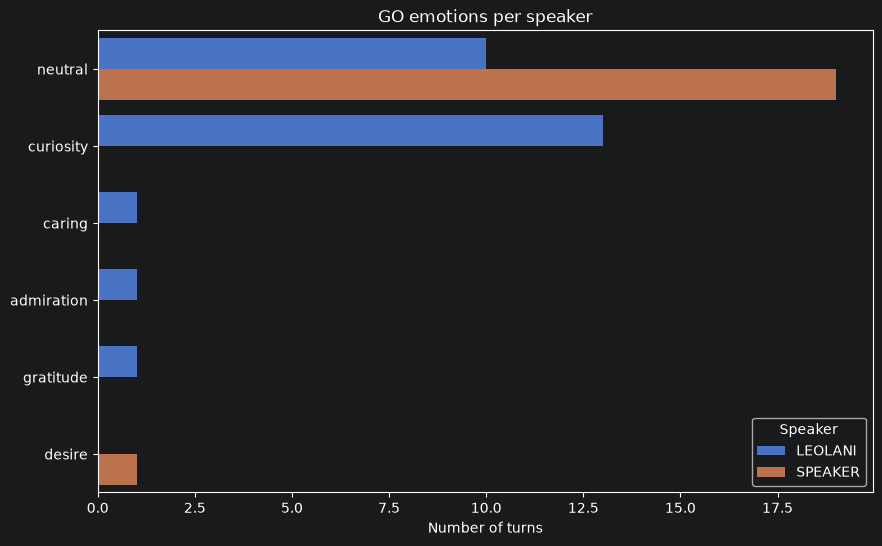

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

order = all_df["go_emotion"].value_counts().index
plt.figure(figsize=(10, 6))
sns.countplot(data=all_df, y="go_emotion", hue="Speaker", order=order)
plt.title("GO emotions per speaker")
plt.xlabel("Number of turns")
plt.ylabel("")
plt.show()

The sentiment gives an overall picture. The next table shows the proportion of positive, negative and neutral turns for each speaker and the average sentiment score:

In [9]:
sentiment_proportions = pd.crosstab(all_df["Speaker"], all_df["sentiment"], normalize="index").round(2)
sentiment_proportions["average_sentiment_score"] = all_df.groupby("Speaker")["sentiment_score"].mean().round(2)
sentiment_proportions

sentiment,neutral,positive,average_sentiment_score
Speaker,,,
LEOLANI,0.38,0.62,0.36
SPEAKER,0.90,0.10,0.05


## Sentiment over the conversation

Does the conversation get more positive or more negative over time? The next plot shows the sentiment score of each turn for each speaker. A sentiment score above 0 is positive and below 0 is negative.

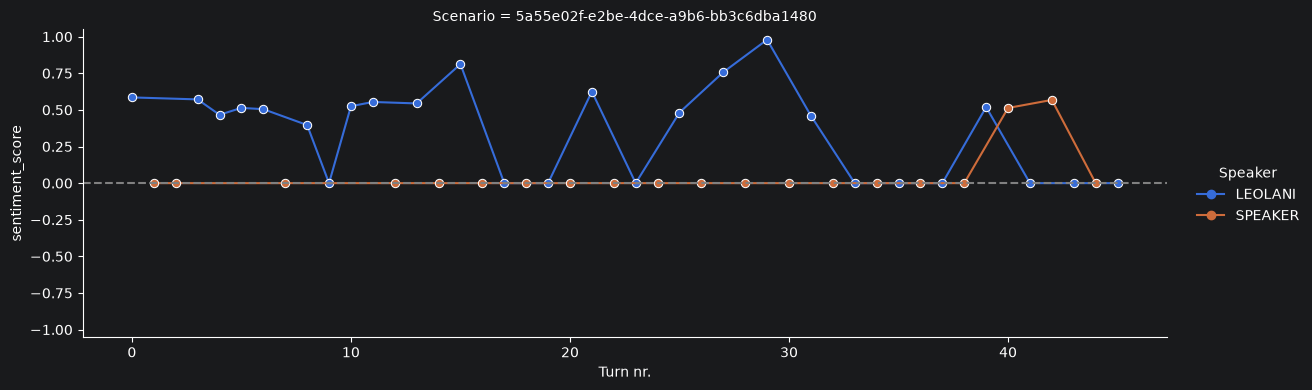

In [10]:
all_df["Turn nr."] = all_df.groupby("Scenario").cumcount()
g = sns.relplot(data=all_df, x="Turn nr.", y="sentiment_score", hue="Speaker", col="Scenario", col_wrap=1,
                kind="line", marker="o", height=4, aspect=3)
g.set(ylim=(-1.05, 1.05))
g.refline(y=0, color="grey", linestyle="--")
plt.show()

## Emotion scores over the conversation

The emotion scores are more fine-grained than the sentiment: love and joy score higher than approval, and anger scores lower than confusion. The next table gives the average emotion score per speaker and the plot shows the emotion score of each turn over the conversation.

In [11]:
all_df.groupby("Speaker")["emotion_score"].agg(["mean", "min", "max", "count"])

,mean,min,max,count
Speaker,,,,
LEOLANI,0.769231,0,3,26
SPEAKER,0.200000,0,4,20


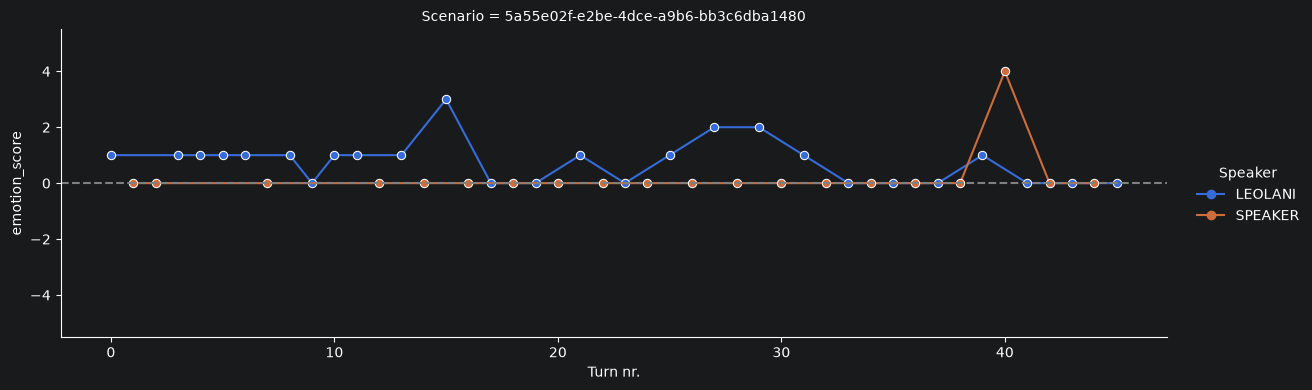

In [12]:
g = sns.relplot(data=all_df, x="Turn nr.", y="emotion_score", hue="Speaker", col="Scenario", col_wrap=1,
                kind="line", marker="o", height=4, aspect=3)
g.set(ylim=(-5.5, 5.5))
g.refline(y=0, color="grey", linestyle="--")
plt.show()

## Emotion transitions

Emotions are contagious: a happy user may make the agent happy and an annoyed agent may annoy the user. The next table counts how often an Ekman emotion of a turn (rows) is followed by an Ekman emotion in the next turn (columns). Turns are only paired within the same scenario.

In [13]:
all_df["previous_ekman_emotion"] = all_df.groupby("Scenario")["ekman_emotion"].shift(1)
transitions = pd.crosstab(all_df["previous_ekman_emotion"], all_df["ekman_emotion"])
transitions

ekman_emotion,joy,neutral
previous_ekman_emotion,,
joy,5,13
neutral,12,15


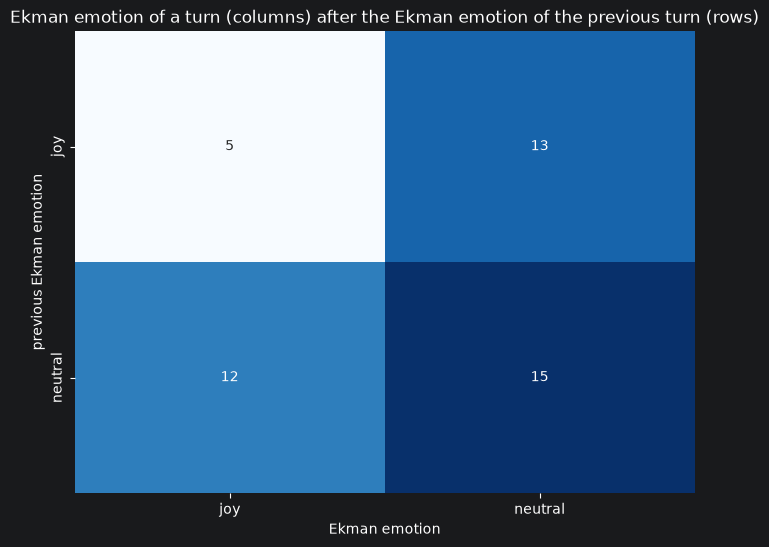

In [14]:
plt.figure(figsize=(8, 6))
sns.heatmap(transitions, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Ekman emotion of a turn (columns) after the Ekman emotion of the previous turn (rows)")
plt.xlabel("Ekman emotion")
plt.ylabel("previous Ekman emotion")
plt.show()

Look at the diagonal: do the speakers mirror each other's emotions? How does the agent respond to negative emotions of the user, and what does the user do after a negative turn of the agent? Which emotions are hard to recognise in short utterances, and when does the model fall back to neutral?

## End of notebook